<a href="https://colab.research.google.com/github/bollepallideepthi/CSA47-DeepLearning/blob/main/DL_lab%20_question.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install tensorflow scikit-learn matplotlib seaborn opencv-python pandas numpy

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import cv2
import time

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    classification_report, precision_score,
    recall_score, f1_score
)

print("TensorFlow Version:", tf.__version__)
print("All libraries imported successfully!")

TensorFlow Version: 2.21.0
All libraries imported successfully!


In [ ]:
import numpy as np

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 0, 0, 1])

weights = np.zeros(2)
bias = 0
learning_rate = 0.1

def step(x):
    return 1 if x >= 0 else 0

for epoch in range(20):
    for i in range(len(X)):
        z = np.dot(X[i], weights) + bias
        prediction = step(z)

        error = y[i] - prediction

        weights += learning_rate * error * X[i]
        bias += learning_rate * error

print("Actual Output | Predicted Output")

for i in range(len(X)):
    prediction = step(np.dot(X[i], weights) + bias)
    print(y[i], "             ", prediction)

print("Weights:", weights)
print("Bias:", bias)

Actual Output | Predicted Output
0               0
0               0
0               0
1               1
Weights: [0.2 0.1]
Bias: -0.20000000000000004


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([[0], [1], [1], [0]])

model = Sequential([
    Dense(8, input_dim=2, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(X, y, epochs=1000, verbose=0)

predictions = model.predict(X)

print("XOR Predictions:")

for i in range(4):
    print(X[i], "Actual:", y[i][0],
          "Predicted:", round(float(predictions[i][0])))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
XOR Predictions:
[0 0] Actual: 0 Predicted: 0
[0 1] Actual: 1 Predicted: 1
[1 0] Actual: 1 Predicted: 1
[1 1] Actual: 0 Predicted: 0


Epoch 1/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 371ms/step - accuracy: 0.1875 - loss: 1.3449 - val_accuracy: 0.2083 - val_loss: 1.3032
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.2188 - loss: 1.2996 - val_accuracy: 0.2500 - val_loss: 1.2679
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step - accuracy: 0.2396 - loss: 1.2590 - val_accuracy: 0.2500 - val_loss: 1.2363
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.2708 - loss: 1.2201 - val_accuracy: 0.2500 - val_loss: 1.2062
Epoch 5/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.2812 - loss: 1.1841 - val_accuracy: 0.2500 - val_loss: 1.1775
Epoch 6/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.3229 - loss: 1.1524 - val_accuracy: 0.2917 - val_loss: 1.1504
Epoch 7/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.3854 - loss: 1.1242 - val_accuracy: 0.3333 - val_loss: 1.1235
Epoch 8/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.4271 - loss: 1.0949 - val_accuracy: 0.3750 - val_loss: 1.

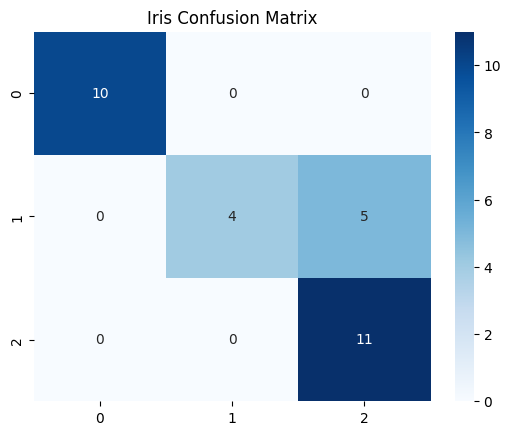

In [ ]:
data = load_iris()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    layers.Input(shape=(4,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    epochs=50,
    validation_split=0.2,
    verbose=1
)

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy)

pred = np.argmax(model.predict(X_test), axis=1)

print(classification_report(y_test, pred))

sns.heatmap(
    confusion_matrix(y_test, pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Iris Confusion Matrix")
plt.show()

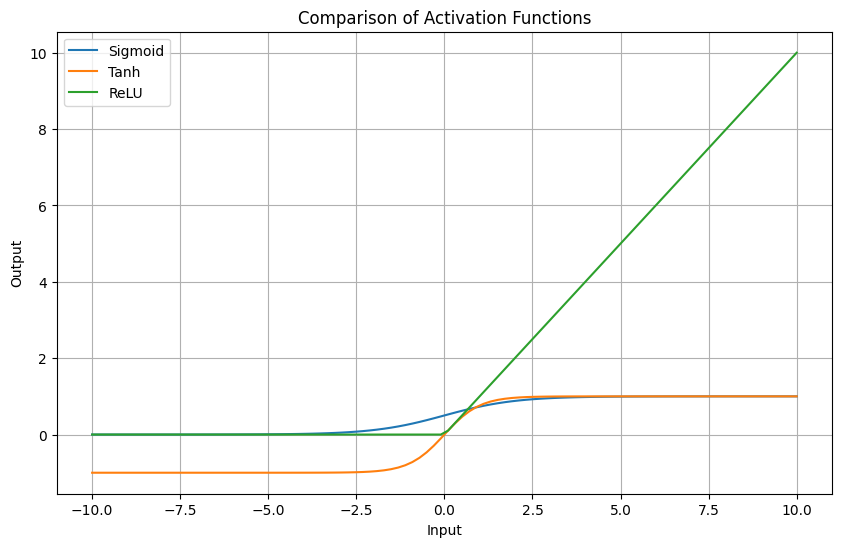

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)

plt.figure(figsize=(10, 6))

plt.plot(x, sigmoid, label='Sigmoid')
plt.plot(x, tanh, label='Tanh')
plt.plot(x, relu, label='ReLU')

plt.title("Comparison of Activation Functions")
plt.xlabel("Input")
plt.ylabel("Output")

plt.legend()
plt.grid()
plt.show()

relu Test Accuracy: 0.9649122953414917
sigmoid Test Accuracy: 0.9912280440330505
tanh Test Accuracy: 0.9824561476707458


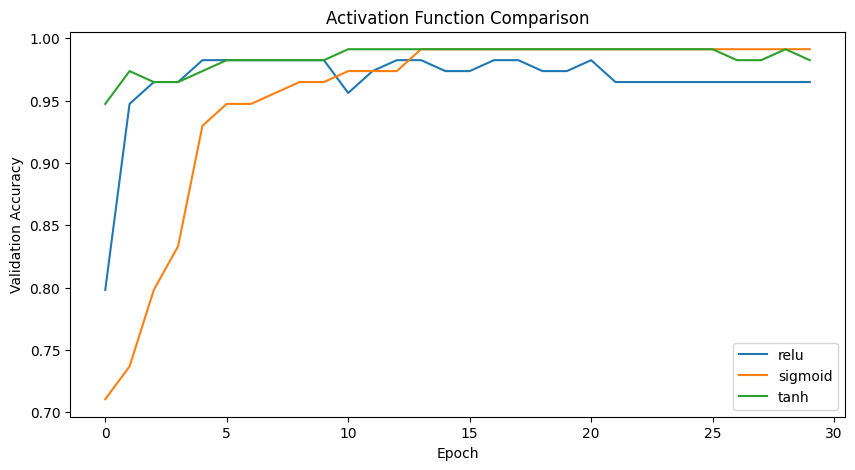

In [ ]:
data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

activations = ['relu', 'sigmoid', 'tanh']

results = {}

for activation in activations:

    model = Sequential([
        layers.Input(shape=(30,)),
        Dense(32, activation=activation),
        Dense(16, activation=activation),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train, y_train,
        epochs=30,
        validation_data=(X_test, y_test),
        verbose=0
    )

    results[activation] = history.history

    print(activation, "Test Accuracy:",
          model.evaluate(X_test, y_test, verbose=0)[1])

plt.figure(figsize=(10, 5))

for activation in activations:
    plt.plot(
        results[activation]['val_accuracy'],
        label=activation
    )

plt.title("Activation Function Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

relu Test Accuracy: 0.9912280440330505
sigmoid Test Accuracy: 0.9912280440330505
tanh Test Accuracy: 0.9912280440330505


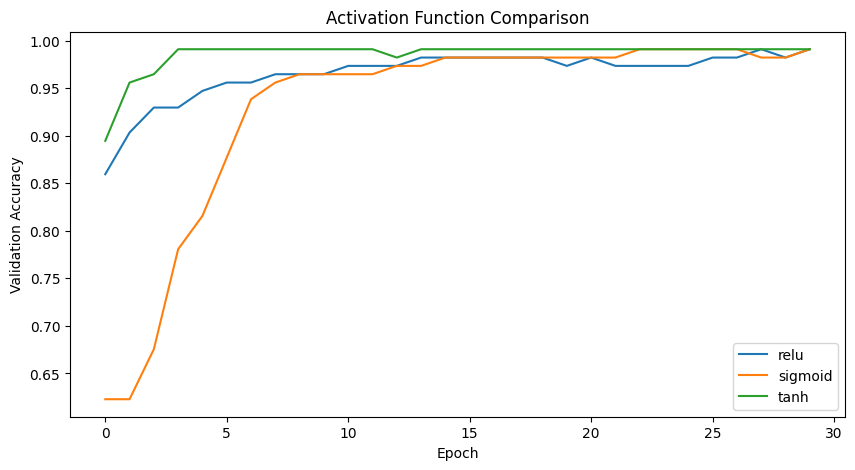

In [ ]:
data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

activations = ['relu', 'sigmoid', 'tanh']

results = {}

for activation in activations:

    model = Sequential([
        layers.Input(shape=(30,)),
        Dense(32, activation=activation),
        Dense(16, activation=activation),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train, y_train,
        epochs=30,
        validation_data=(X_test, y_test),
        verbose=0
    )

    results[activation] = history.history

    print(activation, "Test Accuracy:",
          model.evaluate(X_test, y_test, verbose=0)[1])

plt.figure(figsize=(10, 5))

for activation in activations:
    plt.plot(
        results[activation]['val_accuracy'],
        label=activation
    )

plt.title("Activation Function Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

In [ ]:
import numpy as np

X = np.array([[0.5, 0.2]])

W1 = np.array([
    [0.2, 0.4],
    [0.3, 0.5]
])

b1 = np.array([0.1, 0.1])

W2 = np.array([
    [0.6],
    [0.7]
])

b2 = np.array([0.1])

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Hidden layer
z1 = np.dot(X, W1) + b1
a1 = sigmoid(z1)

# Output layer
z2 = np.dot(a1, W2) + b2
a2 = sigmoid(z2)

print("Input:", X)
print("Hidden Layer Weighted Sum:", z1)
print("Hidden Layer Output:", a1)
print("Output Layer Weighted Sum:", z2)
print("Final Output:", a2)

Input: [[0.5 0.2]]
Hidden Layer Weighted Sum: [[0.26 0.4 ]]
Hidden Layer Output: [[0.56463629 0.59868766]]
Output Layer Weighted Sum: [[0.85786314]]
Final Output: [[0.70221401]]


Final Predictions:
[[0.03 ]
 [0.96 ]
 [0.956]
 [0.051]]


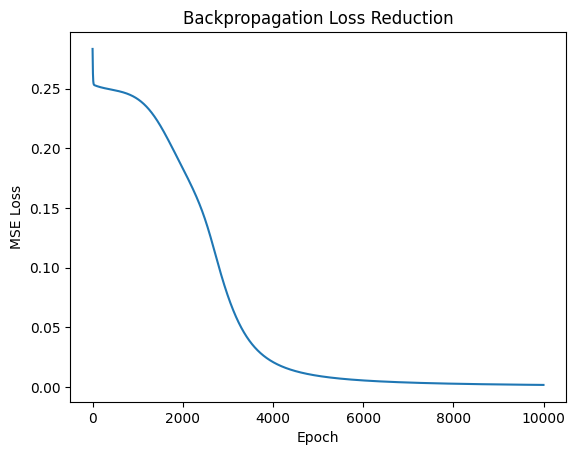

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([[0], [1], [1], [0]])

W1 = np.random.randn(2, 4)
b1 = np.zeros((1, 4))

W2 = np.random.randn(4, 1)
b2 = np.zeros((1, 1))

lr = 0.5
losses = []

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

for epoch in range(10000):

    # Forward propagation
    z1 = X @ W1 + b1
    a1 = sigmoid(z1)

    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)

    # Loss
    loss = np.mean((y - a2) ** 2)
    losses.append(loss)

    # Backpropagation
    dz2 = (a2 - y) * a2 * (1 - a2)

    dW2 = a1.T @ dz2 / len(X)
    db2 = np.mean(dz2, axis=0, keepdims=True)

    dz1 = (dz2 @ W2.T) * a1 * (1 - a1)

    dW1 = X.T @ dz1 / len(X)
    db1 = np.mean(dz1, axis=0, keepdims=True)

    # Update weights
    W2 -= lr * dW2
    b2 -= lr * db2

    W1 -= lr * dW1
    b1 -= lr * db1

print("Final Predictions:")
print(np.round(a2, 3))

plt.plot(losses)
plt.title("Backpropagation Loss Reduction")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.show()

Epoch 1/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 1.0388 - mae: 0.6940 - val_loss: 0.5302 - val_mae: 0.5193
Epoch 2/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4420 - mae: 0.4730 - val_loss: 0.4219 - val_mae: 0.4562
Epoch 3/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3893 - mae: 0.4416 - val_loss: 0.4064 - val_mae: 0.4594
Epoch 4/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3659 - mae: 0.4297 - val_loss: 0.3915 - val_mae: 0.4463
Epoch 5/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3499 - mae: 0.4172 - val_loss: 0.3708 - val_mae: 0.4310
Epoch 6/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3383 - mae: 0.4098 - val_loss: 0.3533 - val_mae: 0.4195
Epoch 7/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3265 - mae: 0.4012 - val_loss: 0.3559 - val_mae: 0.4162
Epoch 8/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3213 - mae: 0.3966 - val_loss: 0.3956 - val_mae: 0.4053
Epoch 9/30
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - lo

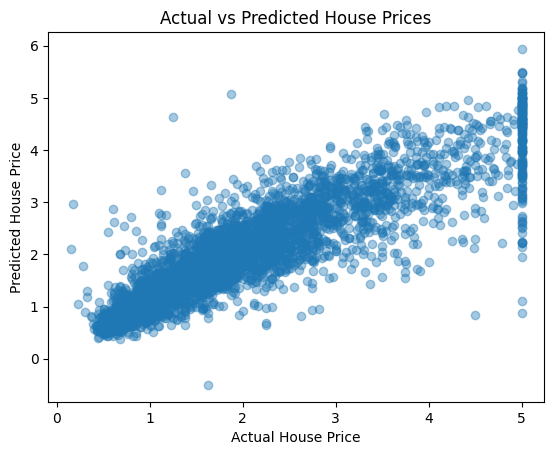

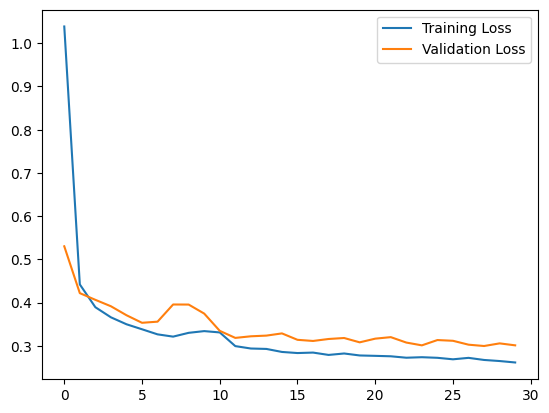

In [ ]:
data = fetch_california_housing()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    layers.Input(shape=(8,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history = model.fit(
    X_train, y_train,
    epochs=30,
    validation_split=0.2,
    verbose=1
)

pred = model.predict(X_test).flatten()

print("Actual Prices:", y_test[:10])
print("Predicted Prices:", pred[:10])

plt.scatter(y_test, pred, alpha=0.4)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.show()

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

In [ ]:
# Download Pima dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    'Pregnancies', 'Glucose', 'BloodPressure',
    'SkinThickness', 'Insulin', 'BMI',
    'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, names=columns)

X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    layers.Input(shape=(8,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train, y_train, epochs=50, verbose=0)

pred = (model.predict(X_test) > 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1 Score:", f1_score(y_test, pred))

print(classification_report(y_test, pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Accuracy: 0.7337662337662337
Precision: 0.6206896551724138
Recall: 0.6545454545454545
F1 Score: 0.6371681415929203
              precision    recall  f1-score   support

           0       0.80      0.78      0.79        99
           1       0.62      0.65      0.64        55

    accuracy                           0.73       154
   macro avg       0.71      0.72      0.71       154
weighted avg       0.74      0.73      0.74       154



29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
SGD Accuracy: 0.8492000102996826
RMSprop Accuracy: 0.8712999820709229
Adam Accuracy: 0.8759999871253967


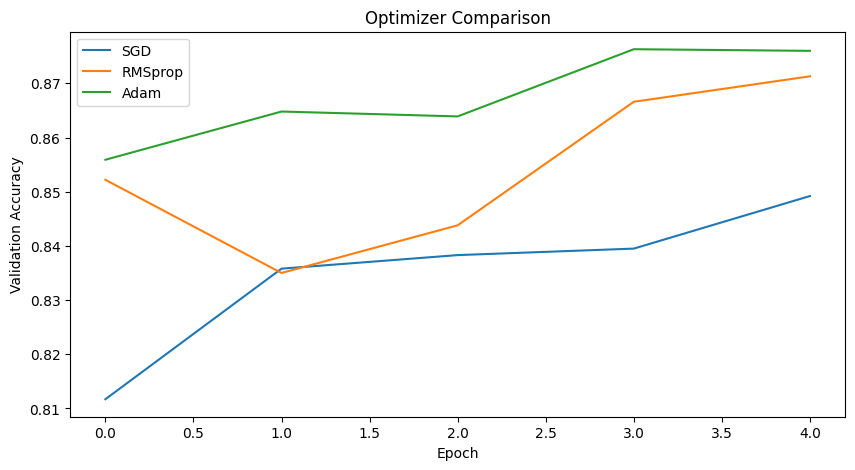

In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255

optimizers = {
    'SGD': keras.optimizers.SGD(),
    'RMSprop': keras.optimizers.RMSprop(),
    'Adam': keras.optimizers.Adam()
}

results = {}

for name, optimizer in optimizers.items():

    model = Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        Dense(128, activation='relu'),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train, y_train,
        epochs=5,
        validation_data=(X_test, y_test),
        verbose=0
    )

    results[name] = history.history

    print(name, "Accuracy:",
          model.evaluate(X_test, y_test, verbose=0)[1])

plt.figure(figsize=(10, 5))

for name in results:
    plt.plot(results[name]['val_accuracy'], label=name)

plt.title("Optimizer Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

PHASE 2: DEEP NEURAL NETWORKS AND REGULARIZATION

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.9271 - loss: 0.2416 - val_accuracy: 0.9568 - val_loss: 0.1453
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.9689 - loss: 0.0998 - val_accuracy: 0.9723 - val_loss: 0.0973
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.9783 - loss: 0.0690 - val_accuracy: 0.9731 - val_loss: 0.0965
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9838 - loss: 0.0525 - val_accuracy: 0.9647 - val_loss: 0.1271
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9862 - loss: 0.0441 - val_accuracy: 0.9716 - val_loss: 0.1013
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9892 - loss: 0.0337 - val_accuracy: 0.9728 - val_loss: 0.1166
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9900 - loss: 0.0304 - val_accuracy: 0.9769 - val_loss: 0.0954
Epoch 8/10
1500/1500 ━━━━━━━━━━

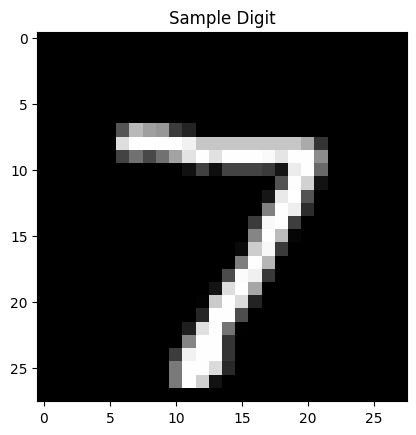

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
Predicted Digit: 7


In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

model = Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(
    X_train, y_train,
    epochs=10,
    validation_split=0.2
)

loss, accuracy = model.evaluate(X_test, y_test)

print("MNIST Test Accuracy:", accuracy)

plt.imshow(X_test[0], cmap='gray')
plt.title("Sample Digit")
plt.show()

print("Predicted Digit:",
      np.argmax(model.predict(X_test[:1])))

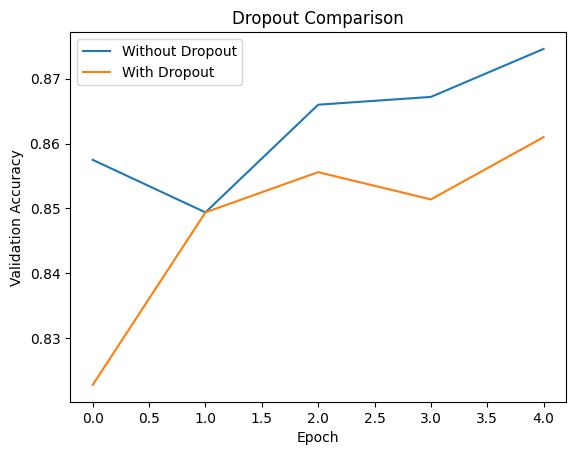

In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

def create_model(dropout=False):

    model = Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        Dense(256, activation='relu')
    ])

    if dropout:
        model.add(layers.Dropout(0.5))

    model.add(Dense(128, activation='relu'))

    if dropout:
        model.add(layers.Dropout(0.3))

    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

model1 = create_model(False)
model2 = create_model(True)

h1 = model1.fit(
    X_train, y_train,
    epochs=5,
    validation_data=(X_test, y_test),
    verbose=0
)

h2 = model2.fit(
    X_train, y_train,
    epochs=5,
    validation_data=(X_test, y_test),
    verbose=0
)

plt.plot(h1.history['val_accuracy'], label='Without Dropout')
plt.plot(h2.history['val_accuracy'], label='With Dropout')

plt.title("Dropout Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

Test Accuracy: 0.9824561476707458


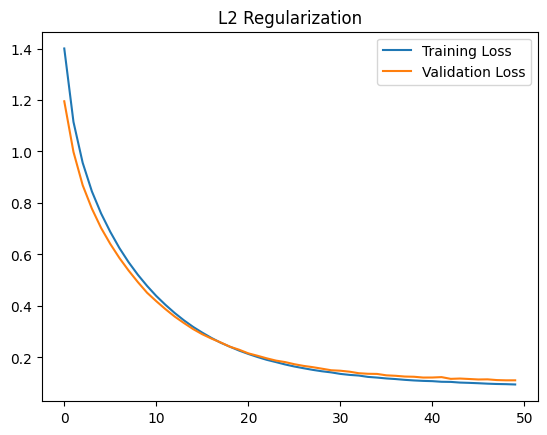

In [ ]:
data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    layers.Input(shape=(30,)),
    Dense(64, activation='relu',
          kernel_regularizer=keras.regularizers.l2(0.01)),
    Dense(32, activation='relu',
          kernel_regularizer=keras.regularizers.l2(0.01)),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    epochs=50,
    validation_data=(X_test, y_test),
    verbose=0
)

print("Test Accuracy:",
      model.evaluate(X_test, y_test, verbose=0)[1])

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("L2 Regularization")
plt.legend()
plt.show()

No Regularization Test Accuracy: 0.8704000115394592
Dropout Test Accuracy: 0.8574000000953674
L2 Test Accuracy: 0.8152999877929688


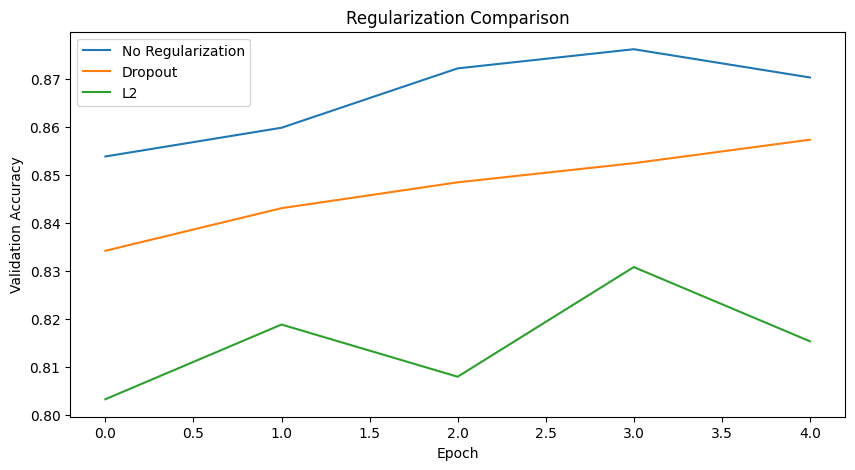

In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

def build_model(reg=None):

    model = Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        Dense(256, activation='relu', kernel_regularizer=reg),
        Dense(128, activation='relu', kernel_regularizer=reg),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

models = {
    'No Regularization': build_model(),
    'Dropout': Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        Dense(256, activation='relu'),
        layers.Dropout(0.5),
        Dense(128, activation='relu'),
        layers.Dropout(0.3),
        Dense(10, activation='softmax')
    ]),
    'L2': build_model(keras.regularizers.l2(0.01))
}

for model in models.values():
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

results = {}

for name, model in models.items():

    history = model.fit(
        X_train, y_train,
        epochs=5,
        validation_data=(X_test, y_test),
        verbose=0
    )

    results[name] = history.history

    print(name, "Test Accuracy:",
          model.evaluate(X_test, y_test, verbose=0)[1])

plt.figure(figsize=(10, 5))

for name in results:
    plt.plot(results[name]['val_accuracy'], label=name)

plt.title("Regularization Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

PHASE 3: CONVOLUTIONAL NEURAL NETWORKS

In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1) / 255.0
X_test = X_test.reshape(-1, 28, 28, 1) / 255.0

model = Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(
    X_train, y_train,
    epochs=5,
    validation_split=0.2
)

print("Test Accuracy:",
      model.evaluate(X_test, y_test)[1])

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy: 0.9555 - loss: 0.1460 - val_accuracy: 0.9861 - val_loss: 0.0487
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 50s 33ms/step - accuracy: 0.9853 - loss: 0.0461 - val_accuracy: 0.9869 - val_loss: 0.0441
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 50s 33ms/step - accuracy: 0.9903 - loss: 0.0309 - val_accuracy: 0.9845 - val_loss: 0.0499
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 51s 34ms/step - accuracy: 0.9933 - loss: 0.0214 - val_accuracy: 0.9892 - val_loss: 0.0378
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 81s 33ms/step - accuracy: 0.9946 - loss: 0.0161 - val_accuracy: 0.9849 - val_loss: 0.0530
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9875 - loss: 0.0415
Test Accuracy: 0.987500011920929


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2048s 12us/step


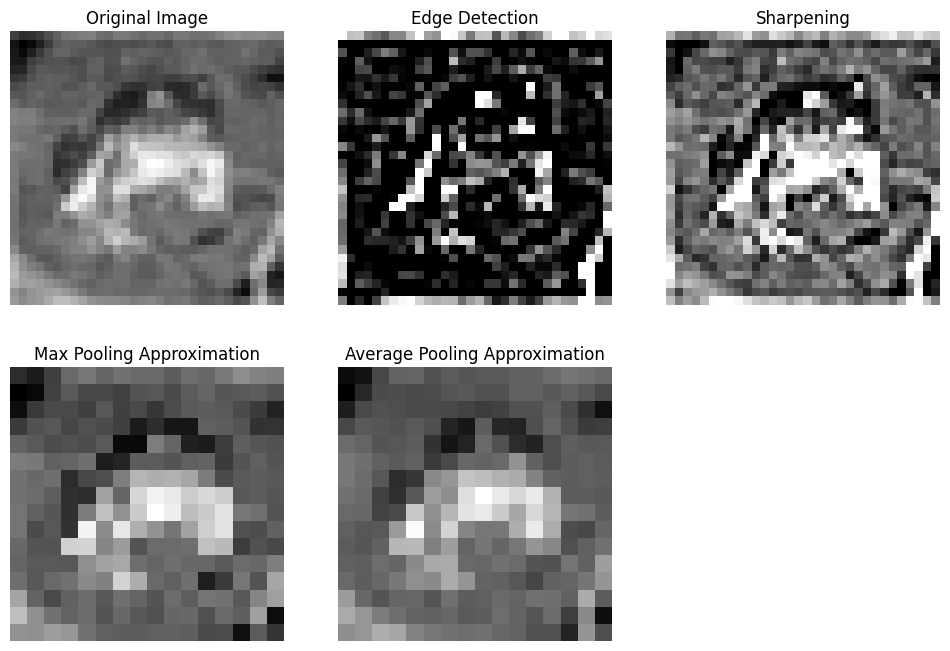

In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

image = X_train[0]

gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

sharp_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

edges = cv2.filter2D(gray, -1, edge_kernel)

sharp = cv2.filter2D(gray, -1, sharp_kernel)

max_pool = cv2.resize(
    gray, (16, 16),
    interpolation=cv2.INTER_NEAREST
)

avg_pool = cv2.resize(
    gray, (16, 16),
    interpolation=cv2.INTER_AREA
)

plt.figure(figsize=(12, 8))

images = [gray, edges, sharp, max_pool, avg_pool]

titles = [
    'Original Image',
    'Edge Detection',
    'Sharpening',
    'Max Pooling Approximation',
    'Average Pooling Approximation'
]

for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.show()

Max Pooling Accuracy: 0.7016000151634216
Average Pooling Accuracy: 0.6796000003814697


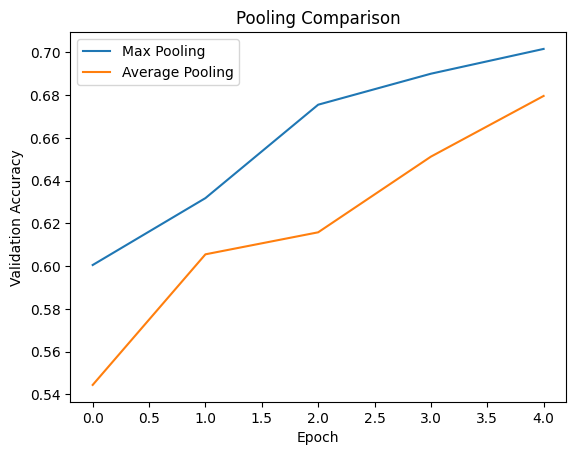

In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

def create_cnn(pooling):

    model = Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation='relu'),
        pooling((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        pooling((2, 2)),
        layers.Flatten(),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

max_model = create_cnn(layers.MaxPooling2D)
avg_model = create_cnn(layers.AveragePooling2D)

h1 = max_model.fit(
    X_train, y_train,
    epochs=5,
    validation_data=(X_test, y_test),
    verbose=0
)

h2 = avg_model.fit(
    X_train, y_train,
    epochs=5,
    validation_data=(X_test, y_test),
    verbose=0
)

print("Max Pooling Accuracy:",
      max_model.evaluate(X_test, y_test, verbose=0)[1])

print("Average Pooling Accuracy:",
      avg_model.evaluate(X_test, y_test, verbose=0)[1])

plt.plot(h1.history['val_accuracy'], label='Max Pooling')
plt.plot(h2.history['val_accuracy'], label='Average Pooling')

plt.title("Pooling Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()